# Ironman 70.3: what decides a finish time, and can we predict it mid-race?

**Data:** 840,075 Ironman 70.3 (half-distance triathlon) results from 195 races, 2004–2020
([Kaggle](https://www.kaggle.com/datasets/aiaiaidavid/ironman-703-race-data-between-2004-and-2020)).

**Questions**
1. How is a 70.3 finish time built up, and how do age, gender and the course change it?
2. **Live race prediction:** at each checkpoint of the race (start, after the swim, after the bike),
   how accurately can we predict the athlete's final finish time?

The second question is a realistic use case: race apps and coaches estimate an athlete's finish time while the race is still running.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

DATA = Path("../data/Half_Ironman_df6.csv")
FIG = Path("../figures"); FIG.mkdir(exist_ok=True)

# One palette for every chart (validated for colour-blind separation)
INK, MUTED, GRID = "#1C211D", "#636A63", "#E4E2DA"
SEG = {"Swim": "#2E7D4F", "Bike": "#C27A3E", "Run": "#C22F7B"}
SEX = {"F": "#C22F7B", "M": "#2E7D4F"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
hms = lambda s: f"{int(s // 3600)}:{int(s % 3600 // 60):02d}"   # seconds -> h:mm

## 1. Load and clean

In [2]:
raw = pd.read_csv(DATA)
print(f"{len(raw):,} rows, {raw['EventLocation'].nunique()} races, {raw['Country'].nunique()} countries")
raw.head()

840,075 rows, 195 races, 240 countries


,Gender,AgeGroup,AgeBand,Country,CountryISO2,EventYear,EventLocation,SwimTime,Transition1Time,BikeTime,Transition2Time,RunTime,FinishTime
0,M,40-44,40,Andorra,AD,2019,IRONMAN 70.3 South American Championship Bueno...,1679,119,9107,95,5515,16514
1,M,45-49,45,Andorra,AD,2019,IRONMAN 70.3 South American Championship Bueno...,2070,177,9160,132,6070,17609
2,M,45-49,45,Andorra,AD,2020,IRONMAN 70.3 Bariloche,1667,161,9891,122,5190,17031
3,M,45-49,45,Andorra,AD,2019,IRONMAN 70.3 World Championship,1750,183,10363,160,5071,17527
4,M,40-44,40,Andorra,AD,2019,IRONMAN 70.3 World Championship,2063,182,10065,142,5556,18008


Two data quality problems:

* **Duplicates.** 17 rows appear twice and are removed.
* **Unknown age group.** 16,611 athletes have `AgeGroup = "00"` and `AgeBand = 0`. Age is unknown for them, so they are removed.
* **The file is sorted by country** (Andorra first). Any `df[:N]` style sample would only contain a few countries,
  so the whole dataset is used instead.

The segment times also add up to the finish time (difference below 60 s for all but one row), so the data is consistent.

In [3]:
segments = ["SwimTime", "Transition1Time", "BikeTime", "Transition2Time", "RunTime"]
gap = (raw["FinishTime"] - raw[segments].sum(axis=1)).abs()

df = raw[(raw["AgeGroup"] != "00") & (gap <= 60)].drop_duplicates().copy()   # 17 exact duplicates
df["FinishMin"] = df["FinishTime"] / 60
print(f"Removed {len(raw) - len(df):,} rows -> {len(df):,} results left")

Removed 16,629 rows -> 823,446 results left


## 2. Exploration

### 2.1 The sport grew fast until 2020

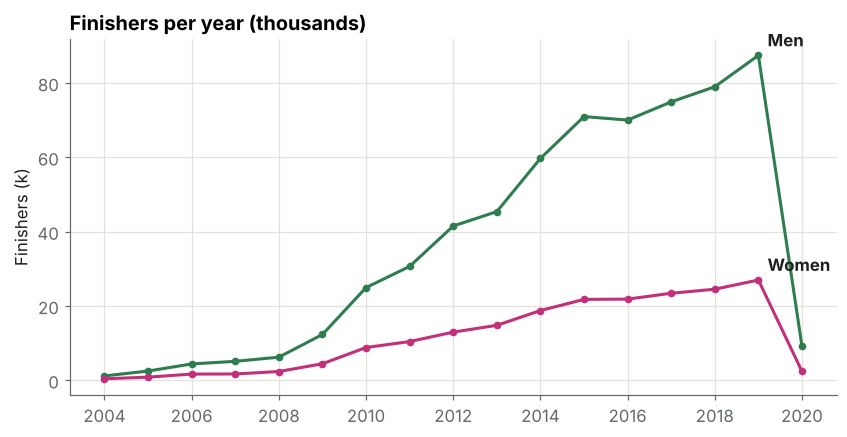

2019: 114,411 finishers, 24% women. 2020 drops because of COVID-19.


In [4]:
per_year = df.groupby(["EventYear", "Gender"]).size().unstack()
fig, ax = plt.subplots(figsize=(9, 4.2))
for g, label in [("M", "Men"), ("F", "Women")]:
    ax.plot(per_year.index, per_year[g] / 1000, color=SEX[g], lw=2, marker="o", ms=4)
    ax.annotate(label, (per_year.index[-2], per_year[g].iloc[-2] / 1000), xytext=(6, 6),
                textcoords="offset points", color=INK, fontweight="bold")
ax.set_title("Finishers per year (thousands)")
ax.set_xlabel(""); ax.set_ylabel("Finishers (k)")
fig.savefig(FIG / "01_finishers_per_year.png"); plt.show()
share_f = per_year.loc[2019, "F"] / per_year.loc[2019].sum()
print(f"2019: {per_year.loc[2019].sum():,} finishers, {share_f:.0%} women. 2020 drops because of COVID-19.")

### 2.2 The bike leg is half of the race

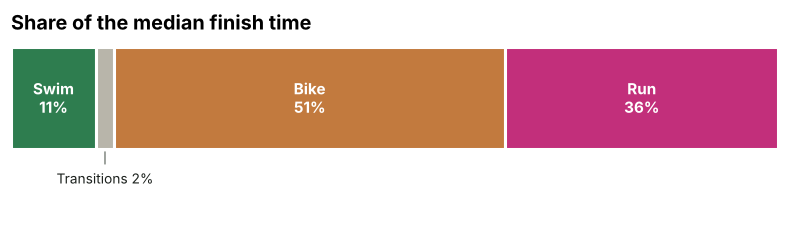

Correlation with finish time: {'SwimTime': 0.63, 'BikeTime': 0.87, 'RunTime': 0.9}


In [5]:
parts = pd.DataFrame({
    "Swim": df["SwimTime"], "Transitions": df["Transition1Time"] + df["Transition2Time"],
    "Bike": df["BikeTime"], "Run": df["RunTime"],
}).div(df["FinishTime"], axis=0).median()
parts = parts / parts.sum()

fig, ax = plt.subplots(figsize=(9, 2.2))
left = 0
colors = {**SEG, "Transitions": "#B8B5AA"}
for name, share in parts.items():
    ax.barh(0, share, left=left, color=colors[name], edgecolor="white", linewidth=2, height=0.6)
    if share >= 0.08:
        ax.text(left + share / 2, 0, f"{name}\n{share:.0%}", ha="center", va="center",
                color="white", fontweight="bold", fontsize=10)
    else:   # small segment: label above the bar
        ax.annotate(f"{name} {share:.0%}", (left + share / 2, -0.3), xytext=(0, -14), textcoords="offset points",
                    ha="center", va="top", color=INK, fontsize=9, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
    left += share
ax.set_xlim(0, 1); ax.set_ylim(-0.75, 0.35); ax.axis("off")
ax.set_title("Share of the median finish time")
fig.savefig(FIG / "02_time_share.png"); plt.show()

corr = df[["SwimTime", "BikeTime", "RunTime"]].corrwith(df["FinishTime"])
print("Correlation with finish time:", corr.round(2).to_dict())

The bike takes about half of the race time, and the run about a third. Bike and run times are also much more
strongly correlated with the finish time than the swim. **Races are mostly decided on the bike and the run.**

### 2.3 Age and gender

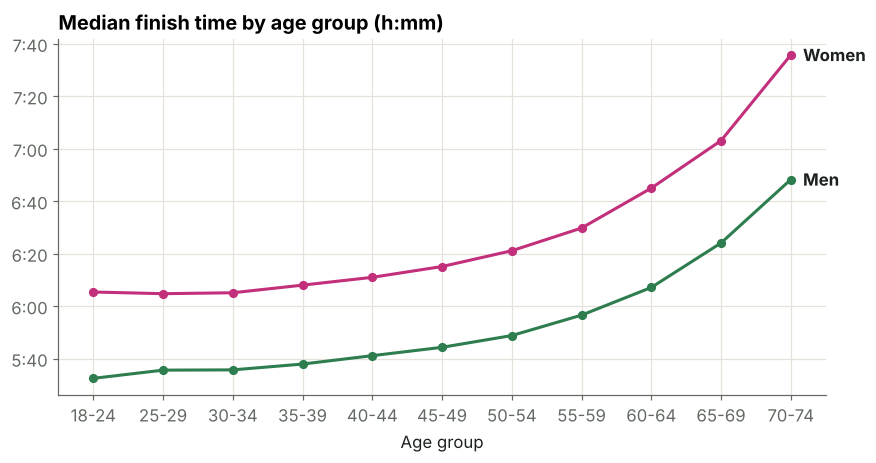

Fastest age group (men): 18-24 | women are ~29 min slower in 30-34


In [6]:
order = sorted(df["AgeGroup"].unique(), key=lambda s: int(s.split("-")[0]))
order = [a for a in order if (df["AgeGroup"] == a).sum() >= 500]   # skip tiny 75+ groups
med = (df[df["AgeGroup"].isin(order)].groupby(["AgeGroup", "Gender"])["FinishMin"].median()
       .unstack().reindex(order))

fig, ax = plt.subplots(figsize=(9, 4.2))
for g, label in [("M", "Men"), ("F", "Women")]:
    ax.plot(range(len(order)), med[g], color=SEX[g], lw=2, marker="o", ms=5)
    ax.annotate(label, (len(order) - 1, med[g].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color=INK, fontweight="bold")
ax.set_xticks(range(len(order)), order)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: hms(v * 60)))
ax.set_title("Median finish time by age group (h:mm)")
ax.set_xlabel("Age group"); ax.set_ylabel("")
fig.savefig(FIG / "03_age_gender.png"); plt.show()

gap_min = (med["F"] - med["M"]).loc["30-34"]
print(f"Fastest age group (men): {med['M'].idxmin()} | women are ~{gap_min:.0f} min slower in 30-34")

### 2.4 The course matters as much as the athlete

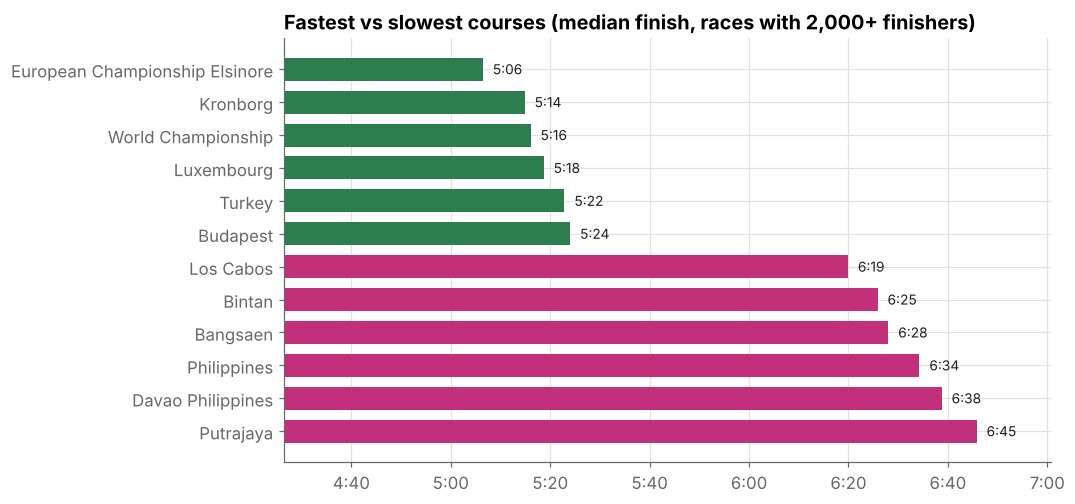

Spread between fastest and slowest course: 99 minutes


In [7]:
ev = df.groupby("EventLocation")["FinishMin"].agg(["median", "size"])
ev = ev[ev["size"] >= 2000].sort_values("median")
pick = pd.concat([ev.head(6), ev.tail(6)])
names = pick.index.str.replace("IRONMAN 70.3 ", "", regex=False).str.slice(0, 32)

fig, ax = plt.subplots(figsize=(9, 5))
colors = [SEG["Swim"]] * 6 + [SEG["Run"]] * 6
ax.barh(range(len(pick)), pick["median"], color=colors, height=0.7)
ax.set_yticks(range(len(pick)), names); ax.invert_yaxis()
ax.set_xlim(pick["median"].min() - 40, pick["median"].max() + 15)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: hms(v * 60)))
for i, v in enumerate(pick["median"]):
    ax.text(v + 2, i, hms(v * 60), va="center", color=INK, fontsize=9)
ax.set_title("Fastest vs slowest courses (median finish, races with 2,000+ finishers)")
fig.savefig(FIG / "04_courses.png"); plt.show()
print(f"Spread between fastest and slowest course: {ev['median'].max() - ev['median'].min():.0f} minutes")

## 3. Live race prediction

**Task:** predict an athlete's final finish time at three checkpoints:

| Checkpoint | What we know |
|---|---|
| **Start** | gender, age, course |
| **After the swim** (T1) | + swim time and first transition |
| **After the bike** (T2) | + bike time and second transition |

**Honest evaluation:** the models are trained on races from **2004–2018** and tested on **2019–2020**.
So the test set is "the future", like it would be in a real app.

**Models**
* **Baseline:** time already raced + the median time of the remaining legs for the same gender and age group
* **Linear regression** (one-hot encoded course)
* **Gradient boosting** (`HistGradientBoostingRegressor`, course as a native categorical feature)

In [8]:
train = df[df["EventYear"] <= 2018]
test = df[df["EventYear"] >= 2019]
print(f"train: {len(train):,} rows | test: {len(test):,} rows | "
      f"{test['EventLocation'].isin(train['EventLocation']).mean():.0%} of test rows are on courses seen in training")

CHECKPOINTS = {
    "Start": [],
    "After swim": ["SwimTime", "Transition1Time"],
    "After bike": ["SwimTime", "Transition1Time", "BikeTime", "Transition2Time"],
}
BASE = ["AgeBand", "Gender", "EventLocation"]
y_tr, y_te = train["FinishTime"], test["FinishTime"]

def baseline(known):
    # elapsed time + median remaining time for the same gender & age group (learned on train)
    remaining = [s for s in segments if s not in known]
    med = train.groupby(["Gender", "AgeGroup"])[remaining].median().sum(axis=1).rename("rem")
    rem = test.join(med, on=["Gender", "AgeGroup"])["rem"].fillna(train[remaining].median().sum())
    return test[known].sum(axis=1) + rem

def linear(known):
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["Gender", "EventLocation"])],
                            remainder="passthrough")
    return Pipeline([("pre", pre), ("model", LinearRegression())])

def boosting(known):
    pre = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan),
                              ["Gender", "EventLocation"])], remainder="passthrough")
    model = HistGradientBoostingRegressor(categorical_features=[0, 1], max_iter=400, learning_rate=0.08,
                                          early_stopping=True, random_state=42)
    return Pipeline([("pre", pre), ("model", model)])

rows, preds = [], {}
for cp, known in CHECKPOINTS.items():
    X_tr, X_te = train[BASE + known], test[BASE + known]
    results = {"Baseline": baseline(known)}
    for name, make in [("Linear regression", linear), ("Gradient boosting", boosting)]:
        results[name] = make(known).fit(X_tr, y_tr).predict(X_te)
    for name, p in results.items():
        rows.append({"Checkpoint": cp, "Model": name,
                     "MAE (min)": mean_absolute_error(y_te, p) / 60, "R²": r2_score(y_te, p)})
    preds[cp] = results["Gradient boosting"]

res = pd.DataFrame(rows)
res.pivot(index="Model", columns="Checkpoint", values="MAE (min)")[list(CHECKPOINTS)].round(1)

train: 697,488 rows | test: 125,958 rows | 84% of test rows are on courses seen in training


Checkpoint,Start,After swim,After bike
Model,,,
Baseline,37.9,33.8,20.0
Gradient boosting,36.3,24.7,12.7
Linear regression,36.5,25.5,12.9


In [9]:
res.pivot(index="Model", columns="Checkpoint", values="R²")[list(CHECKPOINTS)].round(3)

Checkpoint,Start,After swim,After bike
Model,,,
Baseline,0.084,0.269,0.738
Gradient boosting,0.175,0.607,0.890
Linear regression,0.166,0.579,0.887


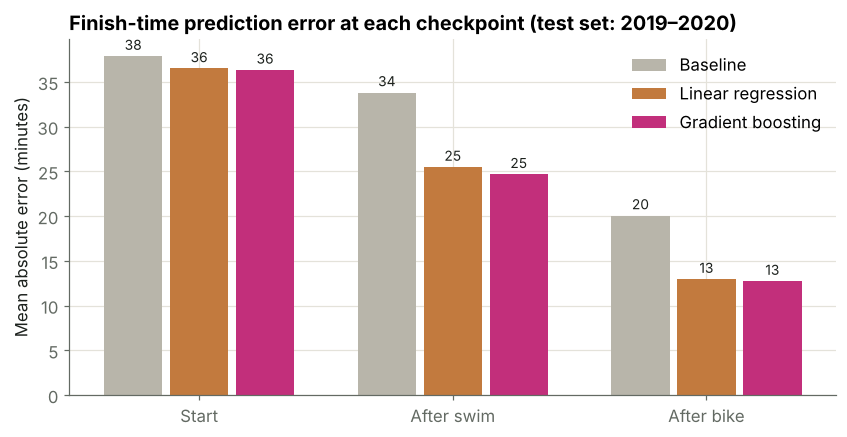

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(CHECKPOINTS)); w = 0.26
mcol = {"Baseline": "#B8B5AA", "Linear regression": SEG["Bike"], "Gradient boosting": SEG["Run"]}
for i, (m, c) in enumerate(mcol.items()):
    v = res[res["Model"] == m].set_index("Checkpoint").loc[list(CHECKPOINTS), "MAE (min)"]
    bars = ax.bar(x + (i - 1) * w, v, width=w - 0.03, color=c, label=m)
    ax.bar_label(bars, fmt="%.0f", padding=2, fontsize=9, color=INK)
ax.set_xticks(x, list(CHECKPOINTS))
ax.set_ylabel("Mean absolute error (minutes)")
ax.set_title("Finish-time prediction error at each checkpoint (test set: 2019–2020)")
ax.legend(frameon=False)
fig.savefig(FIG / "05_error_by_checkpoint.png"); plt.show()

### 3.1 How good is the prediction after the bike?

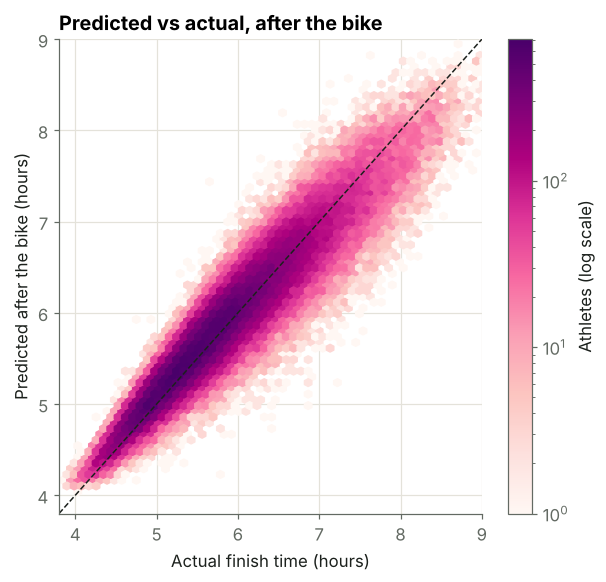

After the bike: 49% of athletes are predicted within ±10 minutes, 80% within ±20 minutes


In [11]:
p = preds["After bike"]
err = (p - y_te) / 60
fig, ax = plt.subplots(figsize=(6.2, 5.6))
hb = ax.hexbin(y_te / 3600, p / 3600, gridsize=70, mincnt=1, bins="log", cmap="RdPu")
lims = [3.8, 9]
ax.plot(lims, lims, color=INK, lw=1, ls="--")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Actual finish time (hours)"); ax.set_ylabel("Predicted after the bike (hours)")
ax.set_title("Predicted vs actual, after the bike")
fig.colorbar(hb, ax=ax, label="Athletes (log scale)")
fig.savefig(FIG / "06_pred_vs_actual.png"); plt.show()
print(f"After the bike: {(err.abs() <= 10).mean():.0%} of athletes are predicted within ±10 minutes, "
      f"{(err.abs() <= 20).mean():.0%} within ±20 minutes")

### 3.2 Prediction intervals: how sure is the model?

A single number hides the uncertainty. With **quantile regression** (the same gradient boosting model, trained to
predict the 10th and 90th percentile) we get an **80% prediction interval**:
*"this athlete will finish between X and Y with 80% probability"*.

We check two things on the test set:
* **Coverage:** how many athletes really finish inside their interval (should be close to 80%).
  Raw quantile models are often a bit over-confident on new data, so the intervals are **calibrated on the 2018 races**
  (conformalized quantile regression) before they are tested on 2019–2020.
* **Width:** how wide the interval is (narrower = more useful)

In [12]:
def quantile_model(q):
    pre = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan),
                              ["Gender", "EventLocation"])], remainder="passthrough")
    model = HistGradientBoostingRegressor(loss="quantile", quantile=q, categorical_features=[0, 1],
                                          max_iter=400, learning_rate=0.08, early_stopping=True, random_state=42)
    return Pipeline([("pre", pre), ("model", model)])

# Conformalized quantile regression (CQR):
# fit the quantile models on 2004-2017, calibrate the interval on 2018, evaluate on 2019-2020.
fit_part, cal_part = train[train["EventYear"] <= 2017], train[train["EventYear"] == 2018]

intervals, irows = {}, []
for cp, known in CHECKPOINTS.items():
    cols = BASE + known
    m_lo = quantile_model(0.10).fit(fit_part[cols], fit_part["FinishTime"])
    m_hi = quantile_model(0.90).fit(fit_part[cols], fit_part["FinishTime"])
    # how far the 2018 athletes fall outside their raw interval
    y_cal = cal_part["FinishTime"].values
    score = np.maximum(m_lo.predict(cal_part[cols]) - y_cal, y_cal - m_hi.predict(cal_part[cols]))
    q = np.quantile(score, 0.80 * (1 + 1 / len(score)))
    lo_raw, hi_raw = m_lo.predict(test[cols]), m_hi.predict(test[cols])
    lo, hi = lo_raw - q, hi_raw + q
    intervals[cp] = (lo, hi)
    inside = lambda a, b: ((y_te >= a) & (y_te <= b)).mean()
    irows.append({"Checkpoint": cp,
                  "Coverage (raw)": inside(lo_raw, hi_raw),
                  "Coverage (calibrated)": inside(lo, hi),
                  "Median width (min)": np.median(hi - lo) / 60})
ivl = pd.DataFrame(irows).set_index("Checkpoint")
ivl.style.format({"Coverage (raw)": "{:.1%}", "Coverage (calibrated)": "{:.1%}", "Median width (min)": "{:.0f}"})

,Coverage (raw),Coverage (calibrated),Median width (min)
Checkpoint,,,
Start,76.2%,79.1%,120
After swim,71.7%,77.5%,77
After bike,70.5%,79.4%,41


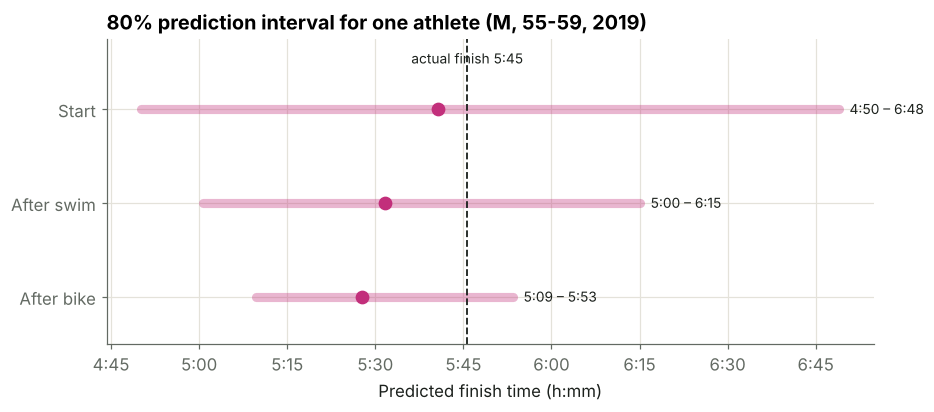

In [13]:
# One real athlete from the test set: how the interval shrinks during the race
pos = int(np.argmin(np.abs(y_te.values - y_te.median())))   # a typical finisher
athlete = test.iloc[pos]
actual = athlete["FinishTime"] / 3600

fig, ax = plt.subplots(figsize=(9, 3.6))
for i, cp in enumerate(CHECKPOINTS):
    lo, hi = intervals[cp][0][pos] / 3600, intervals[cp][1][pos] / 3600
    mid = preds[cp][pos] / 3600
    ax.plot([lo, hi], [i, i], color=SEG["Run"], lw=6, solid_capstyle="round", alpha=0.35)
    ax.plot(mid, i, "o", color=SEG["Run"], ms=8)
    ax.text(hi + 0.03, i, f"{hms(lo*3600)} – {hms(hi*3600)}", va="center", fontsize=9, color=INK)
ax.axvline(actual, color=INK, lw=1.2, ls="--")
ax.text(actual, -0.45, f"actual finish {hms(actual*3600)}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_yticks(range(len(CHECKPOINTS)), list(CHECKPOINTS)); ax.set_ylim(len(CHECKPOINTS) - 0.5, -0.75)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: hms(v * 3600)))
ax.set_xlabel("Predicted finish time (h:mm)")
ax.set_title(f"80% prediction interval for one athlete ({athlete['Gender']}, {athlete['AgeGroup']}, 2019)")
fig.savefig(FIG / "08_interval_example.png"); plt.show()

After calibration, about **79% of athletes finish inside their 80% interval**, so the model is honest about its uncertainty.
The interval shrinks from about 2 hours at the start to about 40 minutes after the bike.

### 3.3 What drives the prediction?

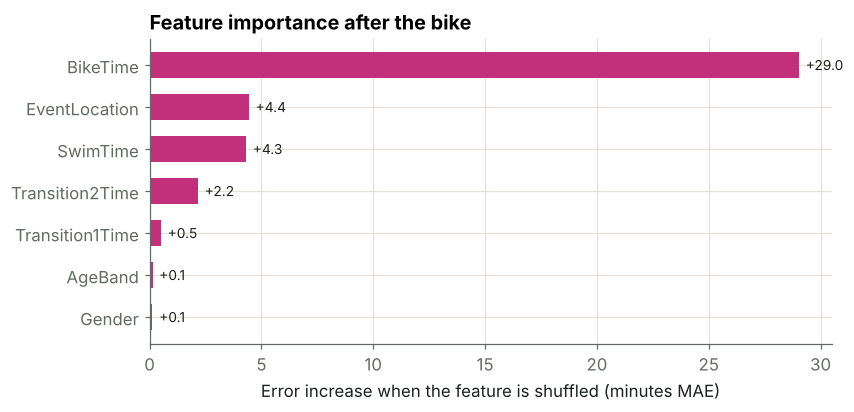

In [14]:
known = CHECKPOINTS["After bike"]
model = boosting(known).fit(train[BASE + known], y_tr)
sample = test.sample(20_000, random_state=0)
imp = permutation_importance(model, sample[BASE + known], sample["FinishTime"], n_repeats=3,
                             random_state=0, scoring="neg_mean_absolute_error")
imp = pd.Series(imp.importances_mean / 60, index=BASE + known).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(imp.index, imp.values, color=SEG["Run"], height=0.6)
for i, v in enumerate(imp.values):
    ax.text(v + 0.3, i, f"+{v:.1f}", va="center", fontsize=9, color=INK)
ax.set_xlabel("Error increase when the feature is shuffled (minutes MAE)")
ax.set_title("Feature importance after the bike")
fig.savefig(FIG / "07_feature_importance.png"); plt.show()

## 4. Conclusions

* **The bike and the run decide the race.** The bike is 51% of the median finish time and the run 36%. Swim time has the weakest correlation with the finish time (0.63 vs 0.87 for the bike and 0.90 for the run).
* **The course matters a lot.** The median finish time differs by about 1 h 40 min between the fastest and the slowest courses (races with 2,000+ finishers). Hot and humid races in Southeast Asia are the slowest.
* **Prediction improves strongly as the race goes on.** On unseen future races (2019–2020), the finish-time error of gradient boosting drops from **36 min** at the start to **25 min** after the swim and **13 min** after the bike (R² = 0.89). After the bike, 49% of athletes are predicted within ±10 minutes and 80% within ±20 minutes.
* **More information beats a more complex model.** Gradient boosting is only slightly better than linear regression. The big gain comes from each new checkpoint, not from the model. Both clearly beat the simple baseline (20 min error after the bike).
* **The model knows how sure it is.** After calibration, the 80% prediction intervals contain 77–79% of the test athletes, and the median interval shrinks from 120 min at the start to 41 min after the bike (see 3.2).
* After the bike, the **bike time** is by far the most important feature, followed by the **course** and the swim time.

**Limitations:** no weather or course elevation data, no history of the athlete's previous races, and athletes who did not finish (DNF) are not in the dataset. So the model only answers: *if this athlete finishes, when?*